## importing libraries

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## importing data

In [2]:
product= pd.read_csv("D:/Yuvraj/messy_products.csv")
order= pd.read_csv("D:/Yuvraj/messy_orders.csv")
order_details= pd.read_csv("D:/Yuvraj/messy_order_items.csv")
customer= pd.read_csv("D:/Yuvraj/messy_customers.csv")


## Data Cleaning

In [3]:
order.isnull().sum()
customer.isnull().sum()
product.isnull().sum()
order_details.isnull().sum()

order_item_id       0
order_id            0
product_id          0
quantity          318
unit_price       1011
dtype: int64

In [4]:
product.drop_duplicates(inplace=True)

In [5]:
order.drop_duplicates(inplace=True)

In [6]:
order_details.drop_duplicates(inplace=True)

In [7]:
customer.drop_duplicates(inplace=True)

In [8]:
order['payment_method']=order['payment_method'].fillna('Unknown')

In [9]:
order['order_date']=pd.to_datetime(order['order_date'],format='mixed')

In [10]:
order_details['quantity']=order_details['quantity'].fillna(round(order_details['quantity'].mean()))

In [11]:
order_details['unit_price']=order_details['unit_price'].fillna(round(order_details['unit_price'].mean()))

In [12]:
customer['customer_name']=customer['customer_name'].fillna('Unknown')

In [13]:
customer['city']=customer['city'].fillna('Unknown')

In [14]:
customer['signup_date']=pd.to_datetime(customer['signup_date'])

In [15]:
customer['city']=customer['city'].replace({'delhi':'Delhi','DELHI':'Delhi','mumbai':'Mumbai','Bangalore':'Bengaluru'})

In [16]:
order['payment_method']=order['payment_method'].replace({'Cash':'Cash on Delivery','upi':'UPI','credit card':'Credit Card'})

In [17]:
product['category']=product['category'].replace({'smart phone':'Smartphone','tablet':'Tablet','laptop':'Laptop','Accessory':'Accessories'})

In [18]:
mean=product.groupby('category')["base_price"].mean().round()

In [19]:
zero_index=order_details[order_details['quantity']==0].index

In [20]:
order_details.drop(index=zero_index)

,order_item_id,order_id,product_id,quantity,unit_price
0,1,O00380,P033,2.0,44852.0
1,2,O00857,P010,1.0,44852.0
2,3,O00589,P007,2.0,77415.0
3,4,O00112,P045,2.0,49066.0
4,5,O00322,P036,2.0,58380.0
...,...,...,...,...,...
1994,1995,O00364,P005,3.0,44852.0
1995,1996,O00944,P007,4.0,64106.0
1996,1997,O00629,P017,4.0,44852.0
1998,1999,O01083,P043,3.0,18251.0


In [21]:
product[product['category']=='Laptop']=product[product['category']=='Laptop'].fillna(mean['Laptop'])
product[product['category']=='Smartphone']=product[product['category']=='Smartphone'].fillna(mean['Smartphone'])
product[product['category']=='Accessories']=product[product['category']=='Accessories'].fillna(mean['Accessories'])
product[product['category']=='Tablet']=product[product['category']=='Tablet'].fillna(mean['Tablet'])

In [22]:
#mapping_value=order_details['product_id'].map(product.set_index('product_id')['base_price'])

In [23]:
#order_details['unit_price']=order_details['unit_price'].fillna(mapping_value)


## Data Transforming

In [24]:
order['Year']=order['order_date'].dt.year

In [25]:
order['Month']=order['order_date'].dt.month_name()

In [26]:
order['Days']=order['order_date'].dt.day_of_year

In [27]:
a=pd.merge(order_details,product,on='product_id')

In [28]:
b=pd.merge(order,customer,on='customer_id')

In [29]:
full_data=pd.merge(a,b,on='order_id')

In [30]:
full_data['Revenue']=full_data['unit_price']*full_data['quantity']

In [31]:
full_data

,order_item_id,order_id,product_id,quantity,unit_price,product_name,category,base_price,customer_id,order_date,payment_method,Year,Month,Days,customer_name,city,signup_date,Revenue
0,1,O00380,P033,2.0,44852.0,Wireless Mouse,Laptop,47453.0,C0014,2024-04-26,Unknown,2024,April,117,Customer_14,Delhi,2024-08-18,89704.0
1,2,O00857,P010,1.0,44852.0,iPhone 13,Smartphone,50189.0,C0196,2024-04-02,Cash on Delivery,2024,April,93,Customer_196,Delhi,2023-05-28,44852.0
2,3,O00589,P007,2.0,77415.0,HP Pavilion,Accessories,44411.0,C0217,2024-09-30,Credit Card,2024,September,274,Customer_217,Pune,2023-04-05,154830.0
3,4,O00112,P045,2.0,49066.0,Lenovo Tab,Laptop,46919.0,C0123,2024-12-27,Debit Card,2024,December,362,Customer_123,Delhi,2024-07-27,98132.0
4,5,O00322,P036,2.0,58380.0,Lenovo IdeaPad,Tablet,40848.0,C0061,2024-03-27,Cash on Delivery,2024,March,87,Customer_61,Hyderabad,2023-06-16,116760.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,1996,O00944,P007,4.0,64106.0,HP Pavilion,Accessories,44411.0,C0014,2024-04-08,Credit Card,2024,April,99,Customer_14,Delhi,2024-08-18,256424.0
1996,1997,O00629,P017,4.0,44852.0,Keyboard,Smartphone,50189.0,C0044,2024-09-16,Cash on Delivery,2024,September,260,Customer_44,Bengaluru,2024-07-16,179408.0
1997,1998,O00703,P008,0.0,76524.0,HP Pavilion,Accessories,44411.0,C0274,2024-02-27,Unknown,2024,February,58,Customer_274,Mumbai,2024-04-08,0.0
1998,1999,O01083,P043,3.0,18251.0,USB Hub,Accessories,44411.0,C0116,2024-08-25,UPI,2024,August,238,Customer_116,Pune,2024-06-06,54753.0


## insight

In [62]:
#Total revenue 
full_data['Revenue'].sum().round()
print("Total revenue is",a//10000000,'cr')

np.float64(179484655.0)

In [33]:
#Highest revenue category
full_data.groupby('category')['Revenue'].sum().sort_values(ascending=False) 


category
Smartphone     57146230.0
Accessories    46292454.0
Tablet         41681662.0
Laptop         34364309.0
Name: Revenue, dtype: float64

## Insights

In [34]:
#Highest revenue product
full_data.groupby('product_name')['Revenue'].sum().sort_values(ascending=False)

product_name
Wireless Mouse    18604807.0
Laptop Bag        17362987.0
Dell Inspiron     17227015.0
Xiaomi Redmi      17141818.0
Samsung Tab       14555154.0
iPhone 13         12927342.0
Lenovo IdeaPad    12607545.0
OnePlus           12181272.0
Samsung Galaxy    10849092.0
Keyboard          10575061.0
Lenovo Tab        10111205.0
USB Hub            9508434.0
iPad Air           7577803.0
HP Pavilion        6861174.0
MacBook Air        1393946.0
Name: Revenue, dtype: float64

In [35]:
#Most sold category
full_data.groupby('category')['quantity'].sum().sort_values(ascending=False)

category
Smartphone     1287.0
Accessories    1014.0
Tablet          916.0
Laptop          781.0
Name: quantity, dtype: float64

In [36]:
#Most sold product
full_data.groupby('product_name')['quantity'].sum().sort_values(ascending=False)

product_name
Wireless Mouse    408.0
Dell Inspiron     386.0
Laptop Bag        379.0
Xiaomi Redmi      373.0
Samsung Tab       316.0
Lenovo IdeaPad    284.0
iPhone 13         281.0
OnePlus           265.0
Samsung Galaxy    248.0
USB Hub           239.0
Keyboard          231.0
Lenovo Tab        222.0
iPad Air          180.0
HP Pavilion       152.0
MacBook Air        34.0
Name: quantity, dtype: float64

In [37]:
#Highest customer from city
full_data.groupby('city')['customer_id'].nunique().sort_values(ascending=False)

city
Delhi        111
Mumbai        71
Bengaluru     63
Hyderabad     45
Pune          41
Unknown       37
Kolkata       29
Chennai       28
Name: customer_id, dtype: int64

In [38]:
#Highest revenue from city
full_data.groupby('city')['Revenue'].sum().sort_values(ascending=False)

city
Delhi        50242479.0
Mumbai       28772851.0
Hyderabad    24638551.0
Bengaluru    22089859.0
Pune         15187502.0
Unknown      14994376.0
Kolkata      12765559.0
Chennai      10793478.0
Name: Revenue, dtype: float64

In [39]:
#Total customer
total_customer = customer["customer_id"].nunique()
print("Total Customers:", customer["customer_id"].nunique())

Total Customers: 500


In [40]:
#Most used payment method
full_data['payment_method'].value_counts()

payment_method
UPI                 523
Credit Card         519
Cash on Delivery    503
Debit Card          235
Unknown             220
Name: count, dtype: int64

In [41]:
#Revenue from payment methods
full_data.groupby('payment_method')['Revenue'].sum().astype(int)

payment_method
Cash on Delivery    45881357
Credit Card         46357849
Debit Card          22118521
UPI                 45725310
Unknown             19401618
Name: Revenue, dtype: int64

In [42]:
full_data.groupby("payment_method")["order_id"].count().sort_values(ascending=False)


payment_method
UPI                 523
Credit Card         519
Cash on Delivery    503
Debit Card          235
Unknown             220
Name: order_id, dtype: int64

In [43]:
#Month wise sales
full_data.groupby('Month')['Revenue'].sum().sort_values(ascending=True)

Month
August        8892784.0
September     9491879.0
November     10192444.0
October      10626948.0
July         11357462.0
June         12182964.0
December     12310334.0
May          16620048.0
February     18884910.0
March        22164798.0
April        22819270.0
January      23940814.0
Name: Revenue, dtype: float64

In [44]:
#Avarage price of categories
full_data.groupby('category')['unit_price'].mean().round().astype(int)

category
Accessories    45386
Laptop         43587
Smartphone     44774
Tablet         45481
Name: unit_price, dtype: int64

In [45]:
#Monthly sales
full_data['month']=full_data['order_date'].dt.to_period('M')
monthly_sales=full_data.groupby('month')['Revenue'].sum().astype(int)
print(monthly_sales)

month
2024-01    15074794
2024-02     9577485
2024-03    12063246
2024-04    11767069
2024-05    11575909
2024-06    11629047
2024-07    11151176
2024-08     8687389
2024-09     9357323
2024-10    10541808
2024-11     8485242
2024-12    12265482
2025-01     8866020
2025-02     9307425
2025-03    10101552
2025-04    11052201
2025-05     5044139
2025-06      553917
2025-07      206286
2025-08      205395
2025-09      134556
2025-10       85140
2025-11     1707202
2025-12       44852
Freq: M, Name: Revenue, dtype: int64


In [46]:
#Top customer by revenue
full_data.groupby('customer_id')['Revenue'].sum().sort_values(ascending=False).head(10).astype(int)#

customer_id
C0218    1854728
C0142    1422750
C0439    1386255
C0474    1378988
C0281    1376224
C0454    1335992
C0339    1279498
C0330    1261121
C0187    1229736
C0233    1229195
Name: Revenue, dtype: int64

In [47]:
#AOV 
aov=full_data['Revenue'].sum()/full_data['order_id'].nunique()
print('AOV is',aov.round())

AOV is 186963.0


## Report

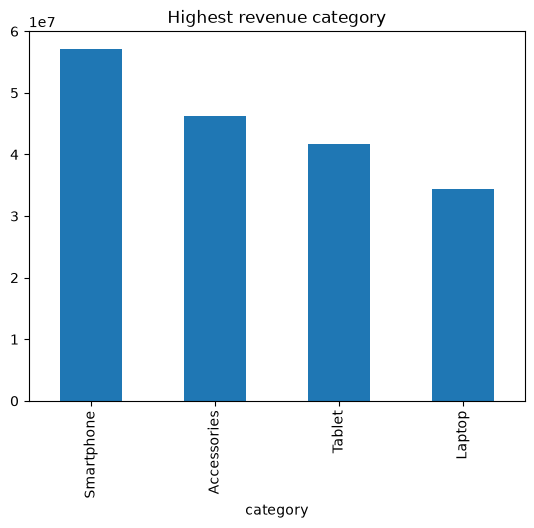

In [48]:
full_data.groupby('category')['Revenue'].sum().sort_values(ascending=False).plot(kind='bar',)
plt.title("Highest revenue category")
plt.show()

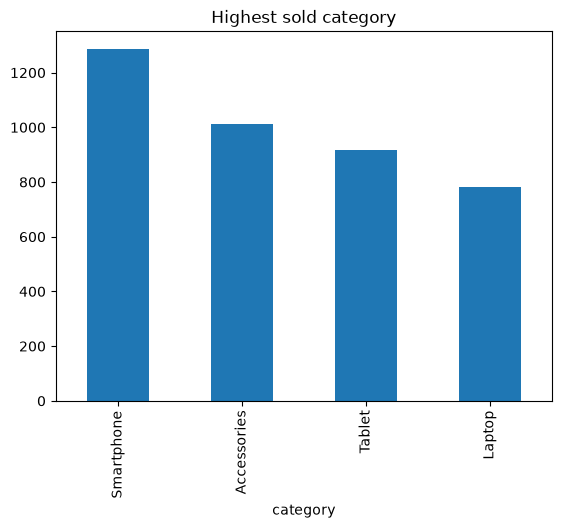

In [49]:
full_data.groupby('category')['quantity'].sum().sort_values(ascending=False).plot(kind='bar',)
plt.title("Highest sold category")
plt.show()

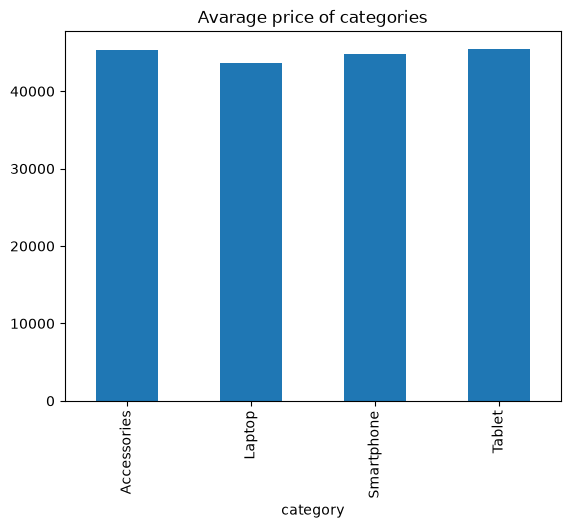

In [50]:
full_data.groupby('category')['unit_price'].mean().round().plot(kind='bar')
plt.title('Avarage price of categories')
plt.show()

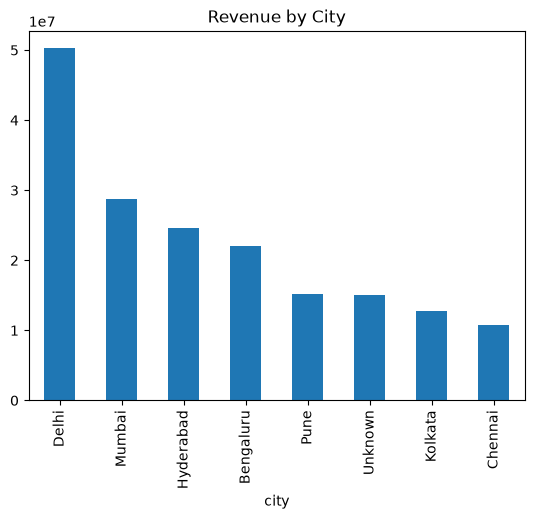

In [51]:
full_data.groupby('city')['Revenue'].sum().sort_values(ascending=False).plot(kind='bar')
plt.title('Revenue by City')
plt.show()

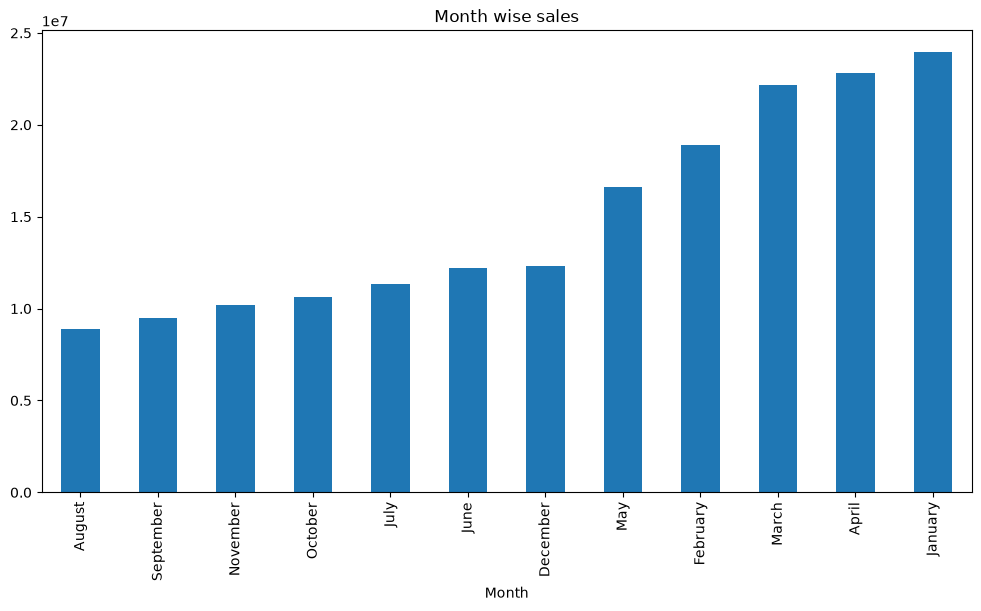

In [52]:
full_data.groupby('Month')['Revenue'].sum().sort_values(ascending=True).plot(kind='bar',figsize=(12,6))
plt.title('Month wise sales')
plt.show()

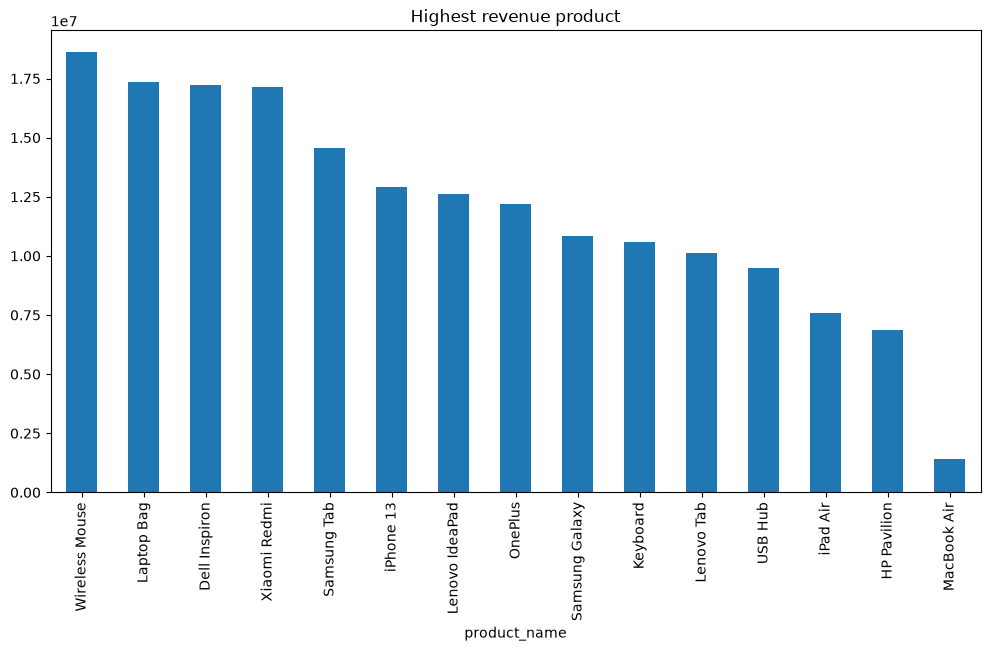

In [53]:
full_data.groupby('product_name')['Revenue'].sum().sort_values(ascending=False).plot(kind='bar',figsize=(12,6))
plt.title('Highest revenue product')
plt.show()

In [54]:
yearly_sales = full_data.groupby('Year')['Revenue'].sum()

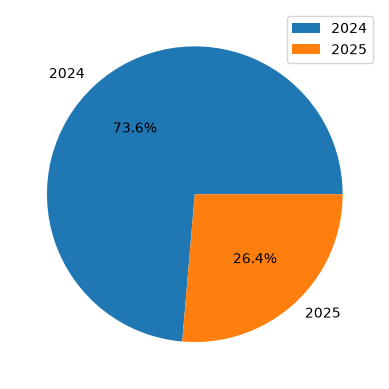

In [55]:
yearly_sales.plot(kind='pie',autopct='%1.1f%%')
plt.legend()
plt.show()

<Axes: xlabel='payment_method'>

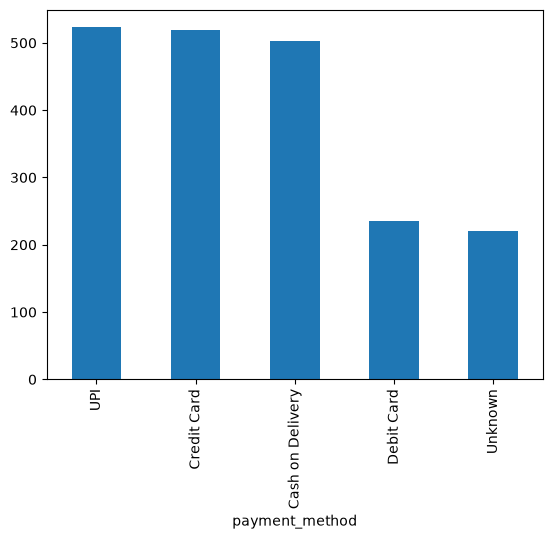

In [56]:
full_data.groupby("payment_method")["order_id"].count().sort_values(ascending=False).plot(kind='bar')

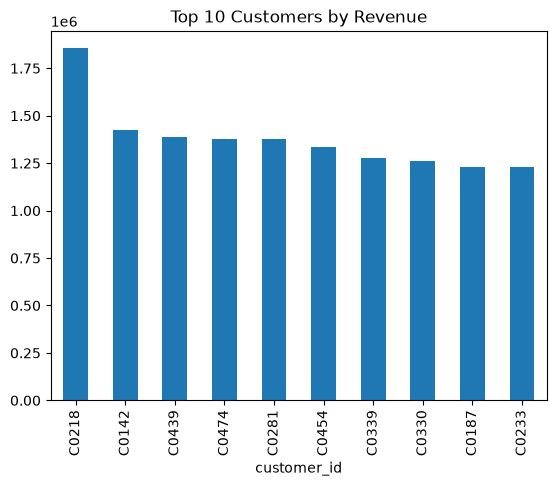

In [57]:
full_data.groupby('customer_id')['Revenue'].sum().sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("Top 10 Customers by Revenue")
plt.show()

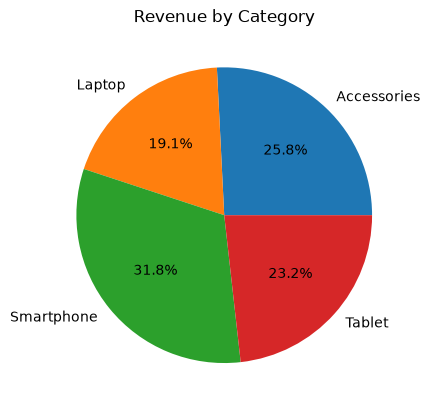

In [58]:
full_data.groupby('category')['Revenue'].sum().plot(kind='pie',autopct='%1.1f%%')
plt.title("Revenue by Category")
plt.show()

<Axes: xlabel='signup_date'>

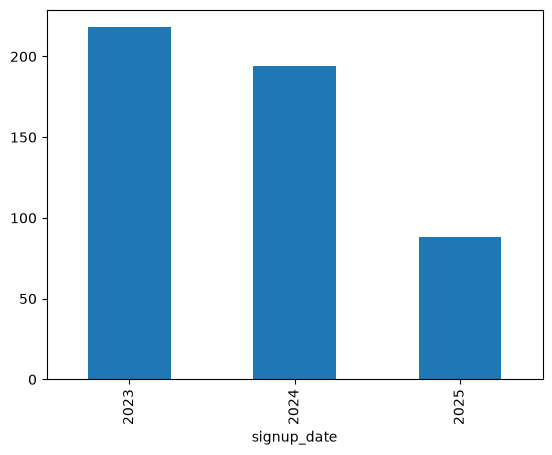

In [59]:
customer.groupby(customer['signup_date'].dt.year).size().plot(kind='bar')